In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

url = "https://raw.githubusercontent.com/johnreygoh/datasets/master/SampleSuperstore.csv"

df = pd.read_csv(url, encoding="latin1")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (9994, 13)


,Ship Mode,Segment,Country,City,State,Postal Code,Region,Category,Sub-Category,Sales,Quantity,Discount,Profit
0,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Bookcases,261.9600,2,0.00,41.9136
1,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Chairs,731.9400,3,0.00,219.5820
2,Second Class,Corporate,United States,Los Angeles,California,90036,West,Office Supplies,Labels,14.6200,2,0.00,6.8714
3,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Furniture,Tables,957.5775,5,0.45,-383.0310
4,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Office Supplies,Storage,22.3680,2,0.20,2.5164


In [ ]:
# Basic information about the dataset

print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
df.describe()

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Ship Mode     9994 non-null   object 
 1   Segment       9994 non-null   object 
 2   Country       9994 non-null   object 
 3   City          9994 non-null   object 
 4   State         9994 non-null   object 
 5   Postal Code   9994 non-null   int64  
 6   Region        9994 non-null   object 
 7   Category      9994 non-null   object 
 8   Sub-Category  9994 non-null   object 
 9   Sales         9994 non-null   float64
 10  Quantity      9994 non-null   int64  
 11  Discount      9994 non-null   float64
 12  Profit        9994 non-null   float64
dtypes: float64(3), int64(2), object(8)
memory usage: 1015.1+ KB

Missing Values:
Ship Mode       0
Segment         0
Country         0
City            0
State           0
Postal Code     0
Region          0
Category        0
S

,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,55190.379428,229.858001,3.789574,0.156203,28.656896
std,32063.693350,623.245101,2.225110,0.206452,234.260108
min,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,56430.500000,54.490000,3.000000,0.200000,8.666500
75%,90008.000000,209.940000,5.000000,0.200000,29.364000
max,99301.000000,22638.480000,14.000000,0.800000,8399.976000


In [ ]:
# Data Cleaning

# Remove duplicate records
df = df.drop_duplicates()

# Convert column names to lowercase
df.columns = df.columns.str.lower().str.replace(" ", "_")

# Check duplicate records
print("Duplicate records:", df.duplicated().sum())

# Check dataset shape
print("Cleaned dataset shape:", df.shape)

# Display cleaned data
df.head()

Duplicate records: 0
Cleaned dataset shape: (9977, 13)


,ship_mode,segment,country,city,state,postal_code,region,category,sub-category,sales,quantity,discount,profit
0,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Bookcases,261.9600,2,0.00,41.9136
1,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Chairs,731.9400,3,0.00,219.5820
2,Second Class,Corporate,United States,Los Angeles,California,90036,West,Office Supplies,Labels,14.6200,2,0.00,6.8714
3,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Furniture,Tables,957.5775,5,0.45,-383.0310
4,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Office Supplies,Storage,22.3680,2,0.20,2.5164


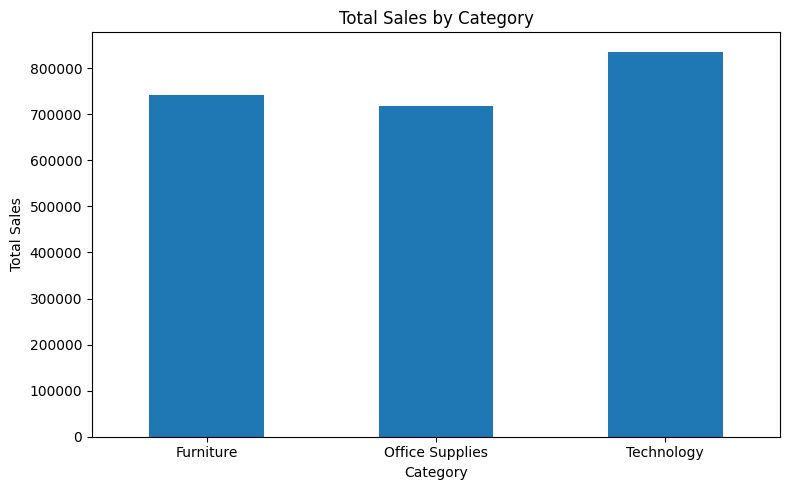

In [ ]:
# Sales by Category

category_sales = df.groupby('category')['sales'].sum()

plt.figure(figsize=(8, 5))
category_sales.plot(kind='bar')

plt.title('Total Sales by Category')
plt.xlabel('Category')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

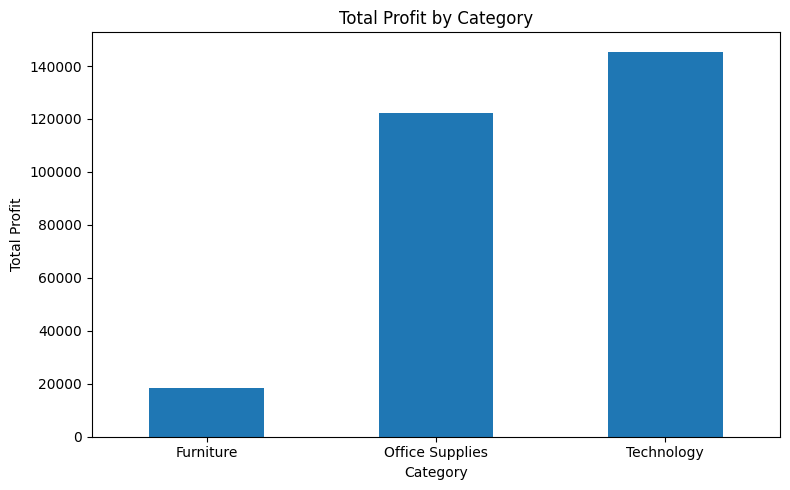

In [ ]:
# Profit by Category

category_profit = df.groupby('category')['profit'].sum()

plt.figure(figsize=(8, 5))
category_profit.plot(kind='bar')

plt.title('Total Profit by Category')
plt.xlabel('Category')
plt.ylabel('Total Profit')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

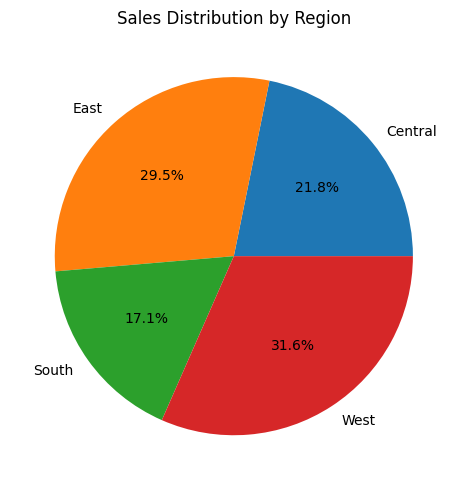

In [ ]:
# Sales by Region

region_sales = df.groupby('region')['sales'].sum()

plt.figure(figsize=(8, 5))
region_sales.plot(kind='pie', autopct='%1.1f%%')

plt.title('Sales Distribution by Region')
plt.ylabel('')
plt.tight_layout()
plt.show()

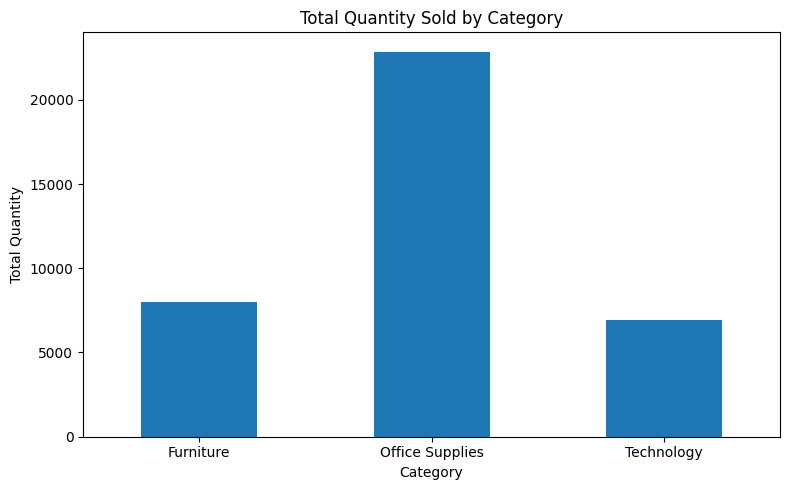

In [ ]:
# Quantity Sold by Category

category_quantity = df.groupby('category')['quantity'].sum()

plt.figure(figsize=(8, 5))
category_quantity.plot(kind='bar')

plt.title('Total Quantity Sold by Category')
plt.xlabel('Category')
plt.ylabel('Total Quantity')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

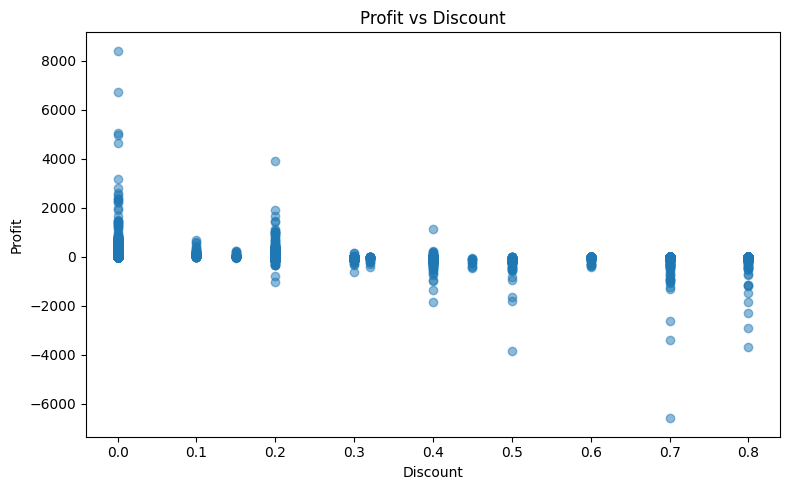

In [ ]:
# Profit vs Discount

plt.figure(figsize=(8, 5))

plt.scatter(df['discount'], df['profit'], alpha=0.5)

plt.title('Profit vs Discount')
plt.xlabel('Discount')
plt.ylabel('Profit')

plt.tight_layout()
plt.show()

In [ ]:
# Business Insights

print("1. Category-wise Sales:")
print(df.groupby('category')['sales'].sum().sort_values(ascending=False))

print("\n2. Category-wise Profit:")
print(df.groupby('category')['profit'].sum().sort_values(ascending=False))

print("\n3. Region-wise Sales:")
print(df.groupby('region')['sales'].sum().sort_values(ascending=False))

print("\n4. Top 5 Best-Selling Products:")
print(df.groupby('product_name')['sales'].sum().sort_values(ascending=False).head(5))

print("\n5. Overall Business Performance:")
print("Total Sales:", round(df['sales'].sum(), 2))
print("Total Profit:", round(df['profit'].sum(), 2))
print("Total Quantity Sold:", df['quantity'].sum())

1. Category-wise Sales:
category
Technology         836154.0330
Furniture          741306.3133
Office Supplies    718735.2440
Name: sales, dtype: float64

2. Category-wise Profit:
category
Technology         145454.9481
Office Supplies    122364.6608
Furniture           18421.8137
Name: profit, dtype: float64

3. Region-wise Sales:
region
West       725255.6365
East       678435.1960
Central    500782.8528
South      391721.9050
Name: sales, dtype: float64

4. Top 5 Best-Selling Products:


KeyError: 'product_name'

In [ ]:
# Business Insights

print("1. Category-wise Sales:")
print(df.groupby('category')['sales'].sum().sort_values(ascending=False))

print("\n2. Category-wise Profit:")
print(df.groupby('category')['profit'].sum().sort_values(ascending=False))

print("\n3. Region-wise Sales:")
print(df.groupby('region')['sales'].sum().sort_values(ascending=False))

print("\n4. Top 5 Cities by Sales:")
print(df.groupby('city')['sales'].sum().sort_values(ascending=False).head(5))

print("\n5. Overall Business Performance:")
print("Total Sales:", round(df['sales'].sum(), 2))
print("Total Profit:", round(df['profit'].sum(), 2))
print("Total Quantity Sold:", df['quantity'].sum())

1. Category-wise Sales:
category
Technology         836154.0330
Furniture          741306.3133
Office Supplies    718735.2440
Name: sales, dtype: float64

2. Category-wise Profit:
category
Technology         145454.9481
Office Supplies    122364.6608
Furniture           18421.8137
Name: profit, dtype: float64

3. Region-wise Sales:
region
West       725255.6365
East       678435.1960
Central    500782.8528
South      391721.9050
Name: sales, dtype: float64

4. Top 5 Cities by Sales:
city
New York City    256319.041
Los Angeles      175831.901
Seattle          119460.282
San Francisco    112577.172
Philadelphia     109061.461
Name: sales, dtype: float64

5. Overall Business Performance:
Total Sales: 2296195.59
Total Profit: 286241.42
Total Quantity Sold: 37820


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

url = "https://raw.githubusercontent.com/johnreygoh/datasets/master/SampleSuperstore.csv"

df = pd.read_csv(url, encoding="latin1")

df = df.drop_duplicates()
df.columns = df.columns.str.lower().str.replace(" ", "_")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (9977, 13)


,ship_mode,segment,country,city,state,postal_code,region,category,sub-category,sales,quantity,discount,profit
0,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Bookcases,261.9600,2,0.00,41.9136
1,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Chairs,731.9400,3,0.00,219.5820
2,Second Class,Corporate,United States,Los Angeles,California,90036,West,Office Supplies,Labels,14.6200,2,0.00,6.8714
3,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Furniture,Tables,957.5775,5,0.45,-383.0310
4,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Office Supplies,Storage,22.3680,2,0.20,2.5164


In [3]:
from google.colab import files

df.to_csv('retail_sales_cleaned.csv', index=False)

files.download('retail_sales_cleaned.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>